# AMPAY VIVO · Comparación 2017-11-01 vs 2026-11-01
**Área de estudio:** Tamburco – Nevado Ampay (Abancay, Apurímac) · área: asset GEE `projects/ee-1005620221/assets/tamburco_glaciar` (respaldo: shapefile embebido)

**Productos:** NDVI, SAVI, NDMI, EVI, NDSI, NDWI · LST diurna y nocturna · T2M · precipitación · radiación solar
**Salidas (una sola carpeta en Drive):** GeoTIFF, PNG (mapas de 3 paneles con leyenda en degradado), CSV, JSON, GeoJSON y SQL para Supabase / geoportal.

▶ **Uso:** `Entorno → Ejecutar todo`. Solo pedirá autorizar Drive y Google Earth Engine.
Ventanas temporales: cada fecha se resume con una ventana de −30 / +7 días (mediana S2, media LST/T2M/radiación, suma de precipitación) para evitar huecos por nubes.

In [1]:
!pip -q install rasterio geopandas

In [3]:
# ── 1. Librerías, Drive y configuración ─────────────────────────────────────
import os, io, json, zipfile, base64, math, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, rasterio, requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from rasterio.features import geometry_mask
from rasterio.io import MemoryFile
from google.colab import drive
drive.mount('/content/drive')

PROYECTO_GEE   = 'ee-1005620221'
ASSET_GEE      = 'projects/ee-1005620221/assets/tamburco_glaciar'
FUENTE_AOI     = 'asset'              # 'asset' (GEE) o 'shapefile' (Drive/embebido)
FECHA_ANTES    = '2017-11-01'
FECHA_DESPUES  = '2026-11-01'
VENT_ATRAS, VENT_ADELANTE = 30, 7     # días alrededor de cada fecha
CS_MIN         = 0.60                 # umbral Cloud Score+ (0-1)
ESC_OPT, ESC_CLIM = 20, 250           # m: Sentinel-2 / clima (remuestreo bilineal)
CRS, NODATA    = 'EPSG:32718', -9999.0
UMBRAL_NIEVE   = 0.40                 # NDSI > 0.4 = nieve/hielo

CARPETA = Path('/content/drive/MyDrive/AMPAY_VIVO_Comparacion_2017_2026')
TMP     = Path('/content/_tmp_gee'); TMP.mkdir(exist_ok=True)
D = {k: CARPETA/k for k in ['datos','geotiff','png','csv','json']}
for d in D.values(): d.mkdir(parents=True, exist_ok=True)
FECHAS = {'antes': FECHA_ANTES, 'despues': FECHA_DESPUES}
print('Carpeta de salida:', CARPETA)

Mounted at /content/drive
Carpeta de salida: /content/drive/MyDrive/AMPAY_VIVO_Comparacion_2017_2026


In [4]:
# ── 2. Base de datos: shapefile tamburco_glaciar → Drive/datos ──────────────
ZIP_B64 = "UEsDBAoAAAAAANW+HF0AAAAAAAAAAAAAAAARABwAdGFtYnVyY29fZ2xhY2lhci9VVAkAA8EfkmoHN/pqdXgLAAEEAAAAAAQAAAAAUEsDBAoAAAAAANW+HF1QPIEOBQAAAAUAAAAlABwAdGFtYnVyY29fZ2xhY2lhci90YW1idXJjb19nbGFjaWFyLmNwZ1VUCQADwR+SahM3+mp1eAsAAQQAAAAABAAAAABVVEYtOFBLAwQUAAAACADVvhxdK81ujdkAAADtAgAAJQAcAHRhbWJ1cmNvX2dsYWNpYXIvdGFtYnVyY29fZ2xhY2lhci5kYmZVVAkAA8EfkmoTN/pqdXgLAAEEAAAAAAQAAAAAY67jkGFkYGBQZDrNgA24e7rEG0OYziCCD4u8AZI8F5q8s3+oX0hQJE55kH5DPPr9HH1doQrA8rzo8j7xMCU4zTdCMp8bm/lGCHlJHOYb4XOfMUK/LJp8mGMQTAl2/VDzccmHRAagmI8u7+rnDlOCPfydYdGHXd7DMdgZn/m8CgGuQXrGeoZ6lvGGCgogngIEBKQWlUJZIBVgWceC0qLDa3MTk0HCfo4KCkgK9AxBShyTEvOSEysVMABCdUhiblJpUXI+phoUZQiWS2ZxSVFmST6MlVyCXZ0UAFBLAwQUAAAACADVvhxdHjleCQQBAACZAQAAJQAcAHRhbWJ1cmNvX2dsYWNpYXIvdGFtYnVyY29fZ2xhY2lhci5wcmpVVAkAA8EfkmoKN/pqdXgLAAEEAAAAAAQAAAAAbY/daoQwEIXfJdepGP9zKZq1LtWIuhQqEoKbugGJENP29Ru3lHa7nYu5OPPNOTNNS49ZN4DnomMIJwE79RV7WZVgKOkALAgt9rFt7BsBME/7UzWA/JfUNY+kpWX+4wRg5McJ8mPHhR5OHC+MPc8PI38cYdOWFbEOhRZCfcjpAqDruCM81WVvfcVs9auE4iD0PeyFCOPA/1qlR5L1Ja0H0GuutnehN8EqoSduVg0skbZpRXrSDuDAFzsjfDNSzQCG7l570B1Tr9pcrhBy3f+wTCij+bIHybPkCsCHOPzDdBNfBDvwaT/Eno8xjm6AJ26keTsLRl8Z1XKW6ubxShhhF5FVxk9QSwMEFAAAAAgA1b4cXeYINl47AAAAbAAAACUAHAB0YW1idXJjb19nbGFjaWFyL3RhbWJ1cmNvX2dsYWNpYXIuc2h4VVQJAAPBH5JqEzf6anV4CwABBAAAAAAEAAAAAGNgUOdiwA7MXjAzMLACGWzRoQ+3s6o5nnhbXTTRKMFx84+ffTuK1RyTi+8IFpsnOOLQjwyMGBiYdwAAUEsDBBQAAAAIANW+HF2+5UpoaAYAANwHAAAlABwAdGFtYnVyY29fZ2xhY2lhci90YW1idXJjb19nbGFjaWFyLnNocFVUCQADwR+SahM3+mp1eAsAAQQAAAAABAAAAACN1Xs01ekaB/AdanLfaTfILZkeZnQx2KRyedCILsh2GTrhMCSETeVWTk6dFJncupiJGqMZZXZymXa1rFFTjRndVJNL1iCZxggVCs3hfK11zmqds+aP8/vr91nv5Vnv+z7v8woEpiqCP/0UB39TFAhm4m9WkG/3hZnEjQNp0jzLEK4ZG8+VJxKHJXbMSbQN4T8f/1/fDMwn/3/mQkdB0r8H9WbKPs2wJh6VX095ZRPC+5YMaDfDpW6bRt7AM4TuseM2xIo+afen4Ij6+a++syM+nhJ8ZwRO93jSJ7In1tatsBqD4w3HToQ5Eauv6RCpIJbiDe2hTldiBSeD+KWwpORgmdEa4vbssVhTOPRs97mfPIgDjt7LXgyHX/itMWYdcWDaSakxrLY1Mrp7PXHUbrmW/vR8+tvuf7+BOK7ZoVoI721545ThRfxcYjLwAvFPm4SP0UbimomXDzrhHj3dLjsf4jT71ppWOLxlU6mJP7GyxcTQXbjK9ch17QDiMbu+wqtwrX/mYCMsjZLc/Abebr6uPv9j4uxfRD+Xweu/m9AQbyJO15uoKp/2yWSni5uJN69wmXMc1uhVXVUeTBwxHml+FNb74+jSxFDi323WSkrgdzS7nI3CiGd5jniehb89GPaOZjhxgyT1ViWs1P9g3/sRxIMlQdKT0+0mAZNRUcT6OhOapfA/BM9PzIshrkw4P3QY3m+UF5IeSzxVOJyUBlv0BMcNwWLv1PPRcKPj1WKtbYhXpH3bH95wwWQqB+3LCx9pOMP3pIKk0/Dzgkf5y+CGpJXXfNFf+26VZBE87u2+YCqOeMtIjKURPKScKR6NJ7ZdVSGaCzftsEl7mEB8xlUkFMAJ2X+Ty6TEMdVKWh3it7nX0uY2/D18vMHIdS3G18l2D+2CHW4W309DfM3yz7194aUGN1o+iSZeYiNTew8+sCSoW2cL5ltwaN4T6xDWCXfvbf+E+NB6F58f4HPRX6gXYH83Zz2KzoIf+71M/QP7r2SfbpEGf/B4mfVcWIWCjyTDHRrH0zxwXg0uXxdIYfuFtV804DyrcsNbQuEcg+4H3vAvJxRsfOFl15NdVOHgjtdzGa4frp54Dz7lbTiqAz8/9GWYQRDxM7NJnwarELY609S3O5B4Rdiiwgp4+FjJTDN4j+VS3Wy4NiVgbQryyWM4yXoHvLvOO7Qf+ZjRfOdOMFxnGunSLCE2c/fTcITb465ceYp81hhIkK2wms7Hvygawbl+ZXOc4EufqbUnIv8tivK3u8LGi0eHZZ7EXtKsEYbdMuIfzYZ3qDdJVsKVPTXXXHB/SqPW1ZjDA7m3ZI64bwqVk579qBWP855m7nEnHt7ZKr0El1kJRVpwwLEGvQq4rSZedxD3915cnlYhLFenh/Vr3taa7K211+bhvjvPcJ57Bz41vk5X6EL8wetZRd3wRwX9GQecibUCLssXIr6pg+otO9SLPcIfv5XCk8mfrhbBLbsatpfDDxvrW684Et8V9Vj/BEf6LhQnwOeH+j9shT1LnGILHIi/EVVXP4PNDvY53l9FfK04z0cN56N8uPmJ+kpi1c2OXjZwXb5X6hYx9i9i9ovpfFn+8pRWJHzjlS8dgHtz9sdHLyOORtGb9qCfcsaUOXFK/CAXwzsLzPPkpsRZ7+p3NsHyI7uMO02IQx0ChBNwdfznOtGGxHOCA1+Ikb8XlU6KC7SRj9q6/qvhneWDZ3K0iHNmREdsgyVdT5MshcT9dWpf7oV/3piV7K+J/Ngq6y6Grx7a4/xPNeJ5HhXJrXBpj93Mj+HM7Qr3puCk8A0Vf1UlvuTd5eSK+yeozG9qUyHOT9GXSqfrYWOqWhksi8yuKIS7fs0uyphN3CsaPiKH//NW6F8N3NsB24xOicPRrmDZ6jld/x8s/iquRxn7bRJ+7l3U2+DrZunpGsQ+JcuHF8A/3DZ2NRURV29st7CFb7a5SHqx3r4pNgyCcy9bNs2eT/x6x7hdDPzZ2aLHQn3iNbU9QQnwjdVOtvWGb9+mr0/PV2kxJnbbF9vuBdspGy5Swv6+cvu7fC2clRxzTIGIjxZ0p4ph28AgTTIjfnrKV28+LJX9fmDb+6hvnY72RrDN4TZBPs7PYIHbfgN410W14sVLUL+qfrw8ifVdMgtSN7d4u97bA6Eu+yyJV4+p+A3BHz5b/iYB7+HNml97XsP/+17+C1BLAQIeAwoAAAAAANW+HF0AAAAAAAAAAAAAAAARABgAAAAAAAAAEAD/QQAAAAB0YW1idXJjb19nbGFjaWFyL1VUBQADwR+SanV4CwABBAAAAAAEAAAAAFBLAQIeAwoAAAAAANW+HF1QPIEOBQAAAAUAAAAlABgAAAAAAAEAAAC2gUsAAAB0YW1idXJjb19nbGFjaWFyL3RhbWJ1cmNvX2dsYWNpYXIuY3BnVVQFAAPBH5JqdXgLAAEEAAAAAAQAAAAAUEsBAh4DFAAAAAgA1b4cXSvNbo3ZAAAA7QIAACUAGAAAAAAAAAAAALaBrwAAAHRhbWJ1cmNvX2dsYWNpYXIvdGFtYnVyY29fZ2xhY2lhci5kYmZVVAUAA8Efkmp1eAsAAQQAAAAABAAAAABQSwECHgMUAAAACADVvhxdHjleCQQBAACZAQAAJQAYAAAAAAABAAAAtoHnAQAAdGFtYnVyY29fZ2xhY2lhci90YW1idXJjb19nbGFjaWFyLnByalVUBQADwR+SanV4CwABBAAAAAAEAAAAAFBLAQIeAxQAAAAIANW+HF3mCDZeOwAAAGwAAAAlABgAAAAAAAAAAAC2gUoDAAB0YW1idXJjb19nbGFjaWFyL3RhbWJ1cmNvX2dsYWNpYXIuc2h4VVQFAAPBH5JqdXgLAAEEAAAAAAQAAAAAUEsBAh4DFAAAAAgA1b4cXb7lSmhoBgAA3AcAACUAGAAAAAAAAAAAALaB5AMAAHRhbWJ1cmNvX2dsYWNpYXIvdGFtYnVyY29fZ2xhY2lhci5zaHBVVAUAA8Efkmp1eAsAAQQAAAAABAAAAABQSwUGAAAAAAYABgBuAgAAqwoAAAAA"
zpath = D['datos']/'tamburco_glaciar.zip'
if not zpath.exists():
    zpath.write_bytes(base64.b64decode(ZIP_B64))
with zipfile.ZipFile(zpath) as z: z.extractall(D['datos'])
SHP = next(D['datos'].rglob('*.shp'))
print('Shapefile:', SHP)

Shapefile: /content/drive/MyDrive/AMPAY_VIVO_Comparacion_2017_2026/datos/tamburco_glaciar/tamburco_glaciar.shp


In [5]:
# ── 3. Conexión a Google Earth Engine ───────────────────────────────────────  # [GEE]
import ee
try:
    ee.Initialize(project=PROYECTO_GEE)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROYECTO_GEE)
print('GEE conectado · proyecto', PROYECTO_GEE)

GEE conectado · proyecto ee-1005620221


In [6]:
# ── 4. Área de estudio (GeoPandas) y malla común ────────────────────────────  # [GEE-AOI]
gdf = None
if FUENTE_AOI == 'asset':
    try:
        fc = ee.FeatureCollection(ASSET_GEE).getInfo()
        gdf = gpd.GeoDataFrame.from_features(fc['features'], crs='EPSG:4326').to_crs(CRS)
        print('AOI: asset GEE ->', ASSET_GEE)
    except Exception as e:
        print('Aviso: no se pudo leer el asset; uso el shapefile de Drive.', e)
if gdf is None:
    gdf = gpd.read_file(SHP).to_crs(CRS); print('AOI: shapefile ->', SHP)
aoi = gdf.dissolve().reset_index(drop=True)
x0, y0, x1, y1 = aoi.total_bounds
SNAP = 1000                                    # alinea la malla 20 m y 250 m
XMIN, YMIN = math.floor(x0/SNAP)*SNAP, math.floor(y0/SNAP)*SNAP
XMAX, YMAX = math.ceil(x1/SNAP)*SNAP,  math.ceil(y1/SNAP)*SNAP
AREA_KM2 = aoi.area.iloc[0]/1e6
BBOX_WGS84 = [float(v) for v in aoi.to_crs(4326).total_bounds]
print(f'Área: {AREA_KM2:.2f} km² · malla UTM 18S: {XMIN},{YMIN} → {XMAX},{YMAX}')

AOI: asset GEE -> projects/ee-1005620221/assets/tamburco_glaciar
Área: 69.32 km² · malla UTM 18S: 721000,8492000 → 736000,8503000


In [7]:
# ── 5. Funciones GEE: Sentinel-2, LST, T2M, precipitación y radiación ───────  # [GEE]
REGION = ee.Geometry.Rectangle([XMIN, YMIN, XMAX, YMAX], CRS, False)
BANDAS_OPT  = ['NDVI','SAVI','NDMI','EVI','NDSI','NDWI']
BANDAS_CLIM = ['LST_dia','LST_noche','T2M','PP','RAD']

def ventana(f):
    d = dt.date.fromisoformat(f)
    return (d - dt.timedelta(days=VENT_ATRAS)).isoformat(), (d + dt.timedelta(days=VENT_ADELANTE+1)).isoformat()

def compuesto_s2(ini, fin):
    col = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(REGION).filterDate(ini, fin)
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 90)))
    cs  = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED').filterBounds(REGION).filterDate(ini, fin)
    col = col.linkCollection(cs, ['cs_cdf'])
    n = col.size().getInfo()
    if n == 0: raise ValueError(f'Sin imágenes Sentinel-2 entre {ini} y {fin}')
    con_cs = col.first().bandNames().contains('cs_cdf').getInfo()
    def prep(img):
        if con_cs: m = img.select('cs_cdf').gte(CS_MIN)
        else:
            qa = img.select('QA60'); m = qa.bitwiseAnd(1024).eq(0).And(qa.bitwiseAnd(2048).eq(0))
        return img.select(['B2','B3','B4','B8','B11']).divide(10000).updateMask(m)
    c = col.map(prep).median()
    N, R, B = c.select('B8'), c.select('B4'), c.select('B2')
    img = ee.Image.cat([
        c.normalizedDifference(['B8','B4']).rename('NDVI'),
        c.expression('1.5*(N-R)/(N+R+0.5)', {'N':N,'R':R}).rename('SAVI'),
        c.normalizedDifference(['B8','B11']).rename('NDMI'),
        c.expression('2.5*(N-R)/(N+6*R-7.5*B+1)', {'N':N,'R':R,'B':B}).clamp(-1,1).rename('EVI'),
        c.normalizedDifference(['B3','B11']).rename('NDSI'),
        c.normalizedDifference(['B3','B8']).rename('NDWI')])
    return img, {'n_imagenes_s2': n, 'mascara_nubes': 'Cloud Score+' if con_cs else 'QA60', 'ventana': [ini, fin]}

def clima_lst(ini, fin):
    bil = lambda i: i.resample('bilinear')
    mod = ee.ImageCollection('MODIS/061/MOD11A1').filterDate(ini, fin).select(['LST_Day_1km','LST_Night_1km']).map(bil)
    era = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR').filterDate(ini, fin)
    n_mod, n_era = mod.size().getInfo(), era.size().getInfo()
    if n_mod == 0 or n_era == 0: raise ValueError(f'Sin datos MODIS/ERA5-Land entre {ini} y {fin}')
    lst = mod.mean().multiply(0.02).subtract(273.15).rename(['LST_dia','LST_noche'])
    t2m = era.select('temperature_2m').map(bil).mean().subtract(273.15).rename('T2M')
    rad = era.select('surface_solar_radiation_downwards_sum').map(bil).mean().divide(1e6).rename('RAD')
    ch  = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate(ini, fin).select('precipitation')
    if ch.size().getInfo() > 0:
        pp, fuente_pp = ch.map(bil).sum().rename('PP'), 'CHIRPS Daily'
    else:
        pp, fuente_pp = era.select('total_precipitation_sum').map(bil).sum().multiply(1000).rename('PP'), 'ERA5-Land'
    return lst.addBands([t2m, pp, rad]), {'n_modis': n_mod, 'n_era5': n_era, 'fuente_pp': fuente_pp}

def bajar(img, escala, nombre, bandas):
    url = (img.select(bandas).toFloat().unmask(NODATA, False).getDownloadURL({
        'name': nombre, 'format': 'GEO_TIFF', 'filePerBand': False, 'crs': CRS,
        'crs_transform': [escala, 0, XMIN, 0, -escala, YMAX], 'region': REGION}))
    r = requests.get(url, timeout=900); r.raise_for_status()
    ruta = TMP/f'{nombre}.tif'
    if r.content[:2] == b'PK':                       # respaldo: un tif por banda en zip
        z = zipfile.ZipFile(io.BytesIO(r.content)); arr = []
        for b in bandas:
            f = [n for n in z.namelist() if n.endswith(f'.{b}.tif')][0]
            with MemoryFile(z.read(f)) as m, m.open() as s: arr.append(s.read(1)); perfil = s.profile
        perfil.update(count=len(arr))
        with rasterio.open(ruta, 'w', **perfil) as d:
            for i, a in enumerate(arr, 1): d.write(a, i)
    else:
        ruta.write_bytes(r.content)
    return ruta

In [8]:
# ── 6. Descarga de rásteres desde GEE (ANTES y DESPUÉS) ─────────────────────  # [GEE]
TIF, INFO = {}, {}
for k, f in FECHAS.items():
    ini, fin = ventana(f)
    print(f'▶ {k} {f}  (ventana {ini} → {fin})')
    img_opt, i1 = compuesto_s2(ini, fin)
    TIF[(k,'opt')] = bajar(img_opt, ESC_OPT, f'opt_{k}', BANDAS_OPT)
    img_cl, i2 = clima_lst(ini, fin)
    TIF[(k,'clim')] = bajar(img_cl, ESC_CLIM, f'clim_{k}', BANDAS_CLIM)
    INFO[k] = {**i1, **i2, 'fecha': f}
    print('   ', INFO[k])

▶ antes 2017-11-01  (ventana 2017-10-02 → 2017-11-09)
    {'n_imagenes_s2': 6, 'mascara_nubes': 'Cloud Score+', 'ventana': ['2017-10-02', '2017-11-09'], 'n_modis': 38, 'n_era5': 38, 'fuente_pp': 'CHIRPS Daily', 'fecha': '2017-11-01'}
▶ despues 2026-11-01  (ventana 2026-10-02 → 2026-11-09)
    {'n_imagenes_s2': 21, 'mascara_nubes': 'Cloud Score+', 'ventana': ['2026-10-02', '2026-11-09'], 'n_modis': 37, 'n_era5': 38, 'fuente_pp': 'ERA5-Land', 'fecha': '2026-11-01'}


In [9]:
# ── 7. Procesamiento: Rasterio + GeoPandas + NumPy ──────────────────────────
VARIABLES = {
 'NDVI':     dict(nombre='NDVI · vigor de vegetación',        unidad='índice', grupo='opt',  cmap='RdYlGn', dif='RdBu',   res_nat=10),
 'SAVI':     dict(nombre='SAVI · vegetación ajustada al suelo', unidad='índice', grupo='opt',  cmap='RdYlGn', dif='RdBu',   res_nat=10),
 'NDMI':     dict(nombre='NDMI · humedad de la vegetación',   unidad='índice', grupo='opt',  cmap='BrBG',   dif='RdBu',   res_nat=20),
 'EVI':      dict(nombre='EVI · índice de vegetación mejorado', unidad='índice', grupo='opt', cmap='YlGn',  dif='RdBu',   res_nat=10),
 'NDSI':     dict(nombre='NDSI · nieve / hielo',              unidad='índice', grupo='opt',  cmap=LinearSegmentedColormap.from_list('nieve',['#8c510a','#f6e8c3','#dff1fb','#4292c6','#08306b']), dif='RdBu', res_nat=20),
 'NDWI':     dict(nombre='NDWI · agua superficial',           unidad='índice', grupo='opt',  cmap='YlGnBu', dif='RdBu',   res_nat=10),
 'LST_dia':  dict(nombre='LST diurna (MODIS MOD11A1)',        unidad='°C',     grupo='clim', cmap='RdYlBu_r', dif='RdBu_r', res_nat=1000),
 'LST_noche':dict(nombre='LST nocturna (MODIS MOD11A1)',      unidad='°C',     grupo='clim', cmap='RdYlBu_r', dif='RdBu_r', res_nat=1000),
 'T2M':      dict(nombre='Temperatura del aire a 2 m (ERA5-Land)', unidad='°C', grupo='clim', cmap='RdYlBu_r', dif='RdBu_r', res_nat=11132),
 'PP':       dict(nombre='Precipitación acumulada en la ventana', unidad='mm', grupo='clim', cmap='YlGnBu', dif='BrBG',   res_nat=5566),
 'RAD':      dict(nombre='Radiación solar descendente (media diaria)', unidad='MJ/m²/día', grupo='clim', cmap='YlOrRd', dif='RdBu_r', res_nat=11132),
}
BANDAS = {'opt': BANDAS_OPT, 'clim': BANDAS_CLIM}
ESC    = {'opt': ESC_OPT, 'clim': ESC_CLIM}

def leer(ruta):
    with rasterio.open(ruta) as s:
        a = s.read().astype('float32'); a[a == NODATA] = np.nan
        return a, s.transform, s.crs

def guardar_tif(a, tr, crs, ruta, desc):
    perfil = dict(driver='GTiff', height=a.shape[0], width=a.shape[1], count=1, dtype='float32',
                  crs=crs, transform=tr, nodata=NODATA, compress='lzw')
    with rasterio.open(ruta, 'w', **perfil) as d:
        d.write(np.where(np.isfinite(a), a, NODATA).astype('float32'), 1); d.set_band_description(1, desc)

def estadisticas(a):
    v = a[np.isfinite(a)]
    if v.size == 0: return dict(n_pix=0, media=np.nan, mediana=np.nan, desv=np.nan, minimo=np.nan, p5=np.nan, p95=np.nan, maximo=np.nan)
    return dict(n_pix=int(v.size), media=float(v.mean()), mediana=float(np.median(v)), desv=float(v.std()),
                minimo=float(v.min()), p5=float(np.percentile(v,5)), p95=float(np.percentile(v,95)), maximo=float(v.max()))

R = {}      # R[var] = dict(antes, despues, dif, transform, crs, esc)
for grupo in ['opt', 'clim']:
    datos = {k: leer(TIF[(k, grupo)]) for k in FECHAS}
    (a_a, tr, crs), (a_d, tr_d, _) = datos['antes'], datos['despues']
    assert a_a.shape == a_d.shape and tr == tr_d, 'Las mallas ANTES/DESPUÉS no coinciden'
    dentro = geometry_mask(aoi.geometry, out_shape=a_a.shape[1:], transform=tr, invert=True, all_touched=(grupo == 'clim'))
    for i, v in enumerate(BANDAS[grupo]):
        A = np.where(dentro, a_a[i], np.nan); B = np.where(dentro, a_d[i], np.nan)
        R[v] = dict(antes=A, despues=B, dif=B - A, transform=tr, crs=crs, esc=ESC[grupo])

# GeoTIFF por variable y periodo
RUTAS = {}
fa, fd = FECHA_ANTES, FECHA_DESPUES
for v, r in R.items():
    for tipo, arr, nom in [('antes', r['antes'], f'{v}_{fa}.tif'), ('despues', r['despues'], f'{v}_{fd}.tif'),
                           ('diferencia', r['dif'], f'{v}_dif_{fa}_{fd}.tif')]:
        guardar_tif(arr, r['transform'], r['crs'], D['geotiff']/nom, f'{v} {tipo}')
        RUTAS[(v, tipo)] = nom

# Estadísticas zonales + superficie con nieve (NDSI > umbral)
filas = []
for v, r in R.items():
    for tipo in ['antes', 'despues', 'dif']:
        s = estadisticas(r[tipo]); s.update(variable=v, tipo={'dif':'diferencia'}.get(tipo, tipo), unidad=VARIABLES[v]['unidad'])
        if v == 'NDSI' and tipo != 'dif':
            s['area_nieve_km2'] = float(np.nansum(r[tipo] > UMBRAL_NIEVE) * (r['esc']/1000)**2)
        filas.append(s)
ST = pd.DataFrame(filas)
cols = ['variable','tipo','unidad','n_pix','media','mediana','desv','minimo','p5','p95','maximo','area_nieve_km2']
ST = ST.reindex(columns=cols)
display(ST.round(3))

,variable,tipo,unidad,n_pix,media,mediana,desv,minimo,p5,p95,maximo,area_nieve_km2
0,NDVI,antes,índice,96380,0.388,0.404,0.180,-0.155,0.064,0.637,0.796,NaN
1,NDVI,despues,índice,173304,0.360,0.348,0.187,-0.157,0.071,0.655,0.828,NaN
2,NDVI,diferencia,índice,96380,0.049,0.047,0.084,-0.640,-0.078,0.181,0.502,NaN
3,SAVI,antes,índice,96380,0.215,0.220,0.109,-0.127,0.036,0.395,0.643,NaN
4,SAVI,despues,índice,173304,0.195,0.190,0.107,-0.125,0.037,0.377,0.659,NaN
5,SAVI,diferencia,índice,96380,0.023,0.020,0.057,-0.467,-0.060,0.116,0.392,NaN
6,NDMI,antes,índice,96380,0.021,0.003,0.184,-0.441,-0.231,0.277,0.929,NaN
7,NDMI,despues,índice,173304,-0.051,-0.091,0.180,-0.492,-0.273,0.254,0.946,NaN
8,NDMI,diferencia,índice,96380,0.000,0.019,0.141,-1.196,-0.160,0.136,0.751,NaN
9,EVI,antes,índice,96380,0.284,0.286,0.155,-0.398,0.047,0.547,1.000,NaN


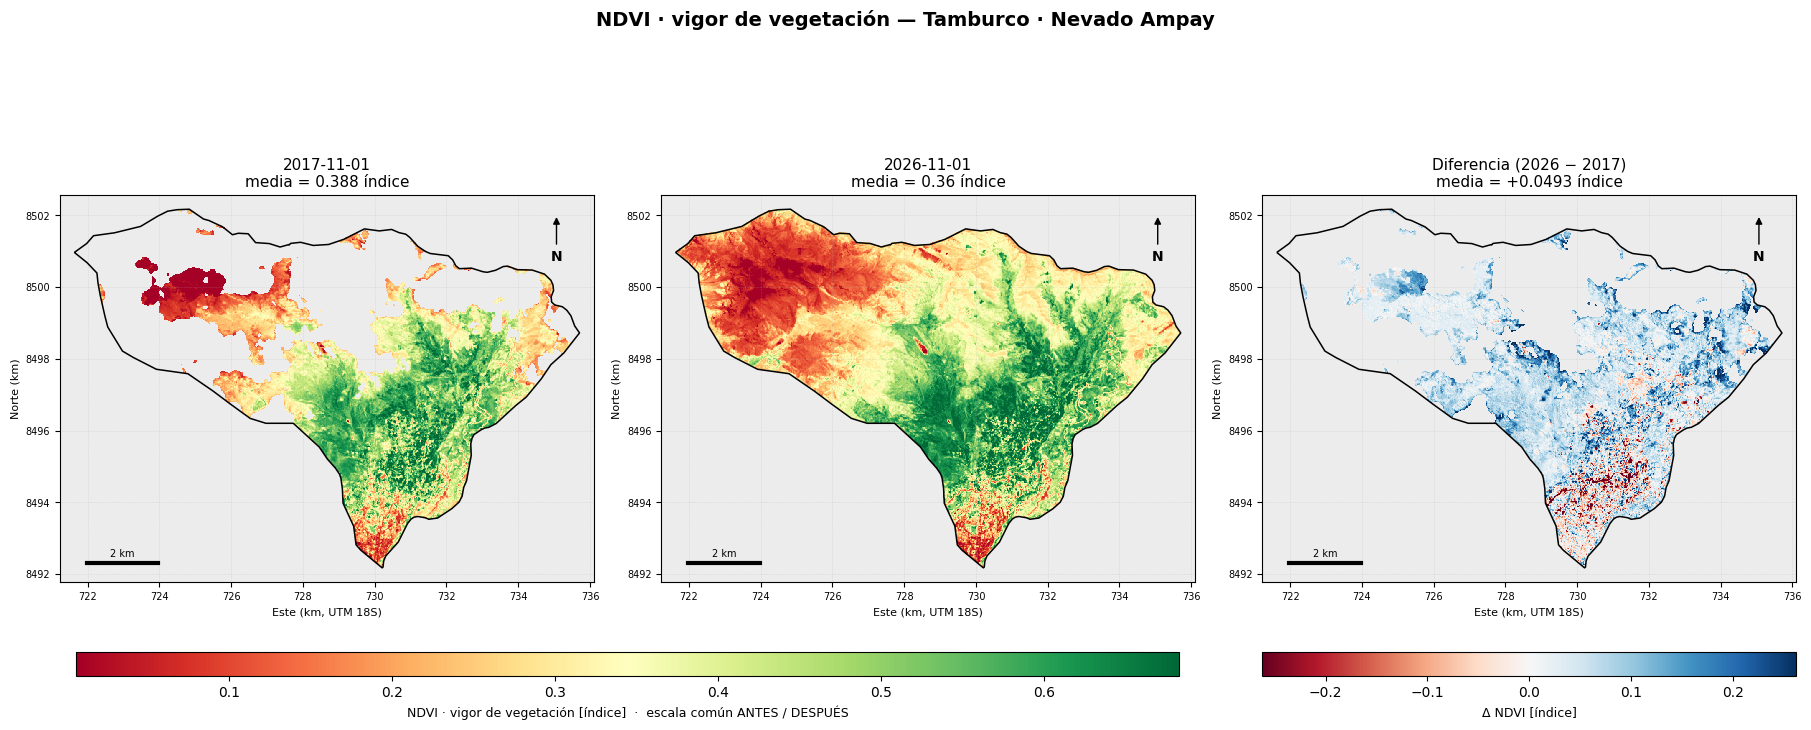

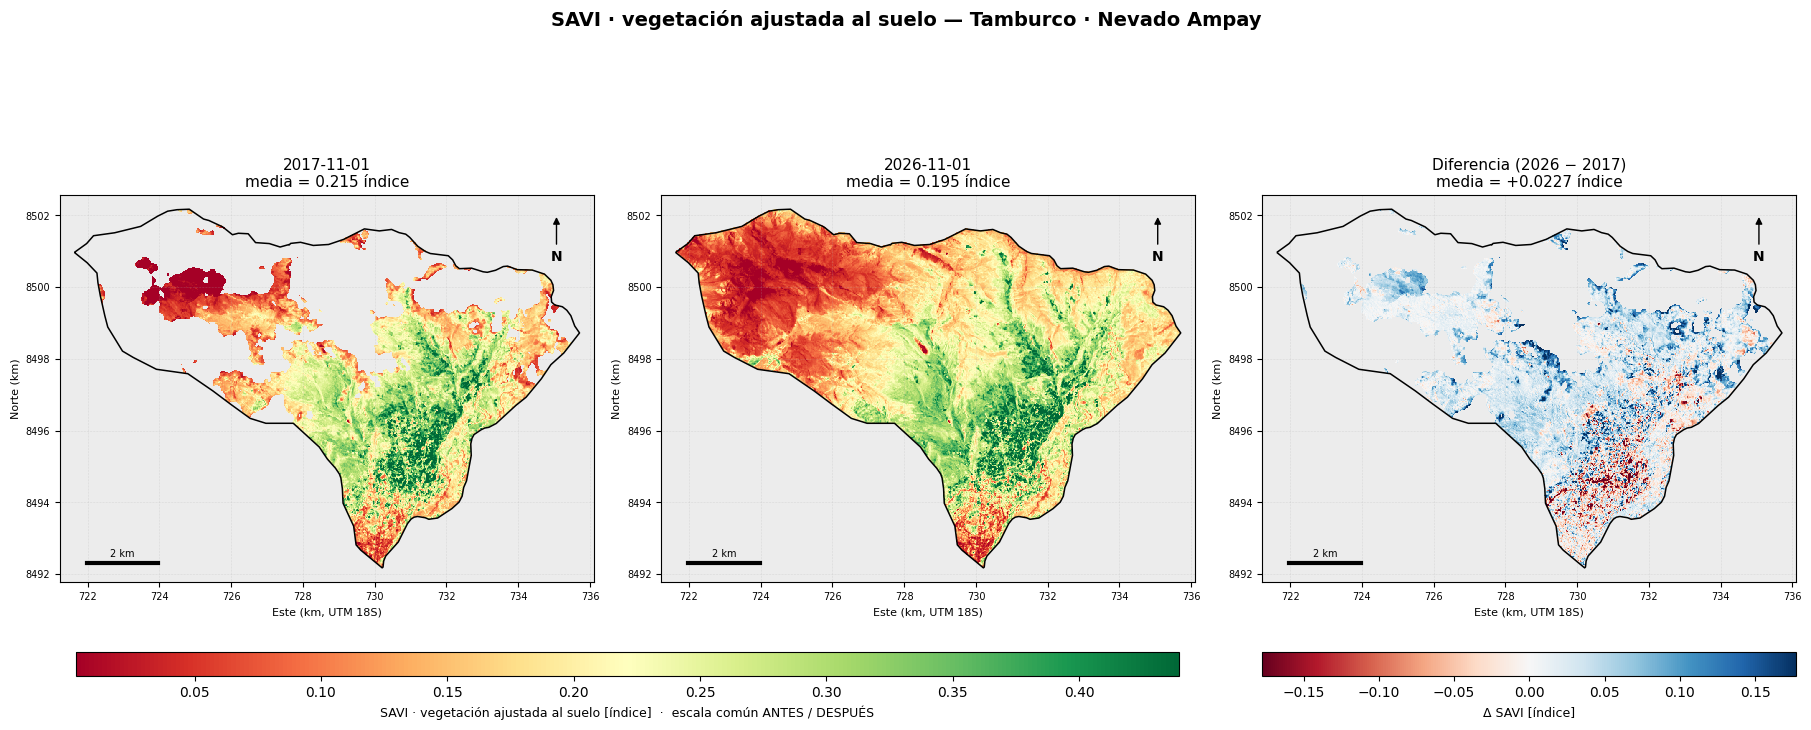

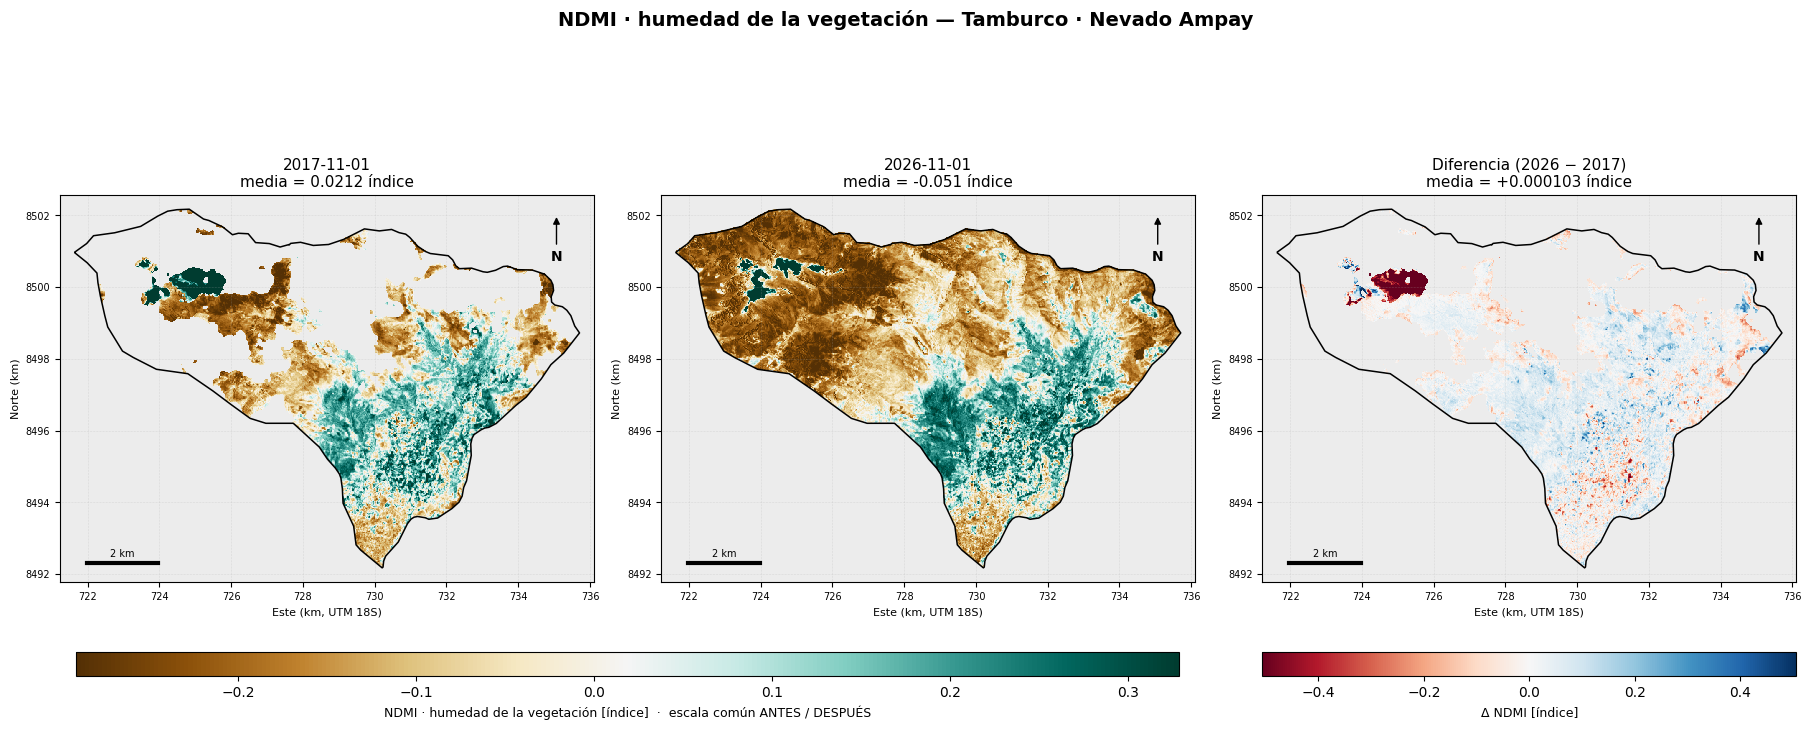

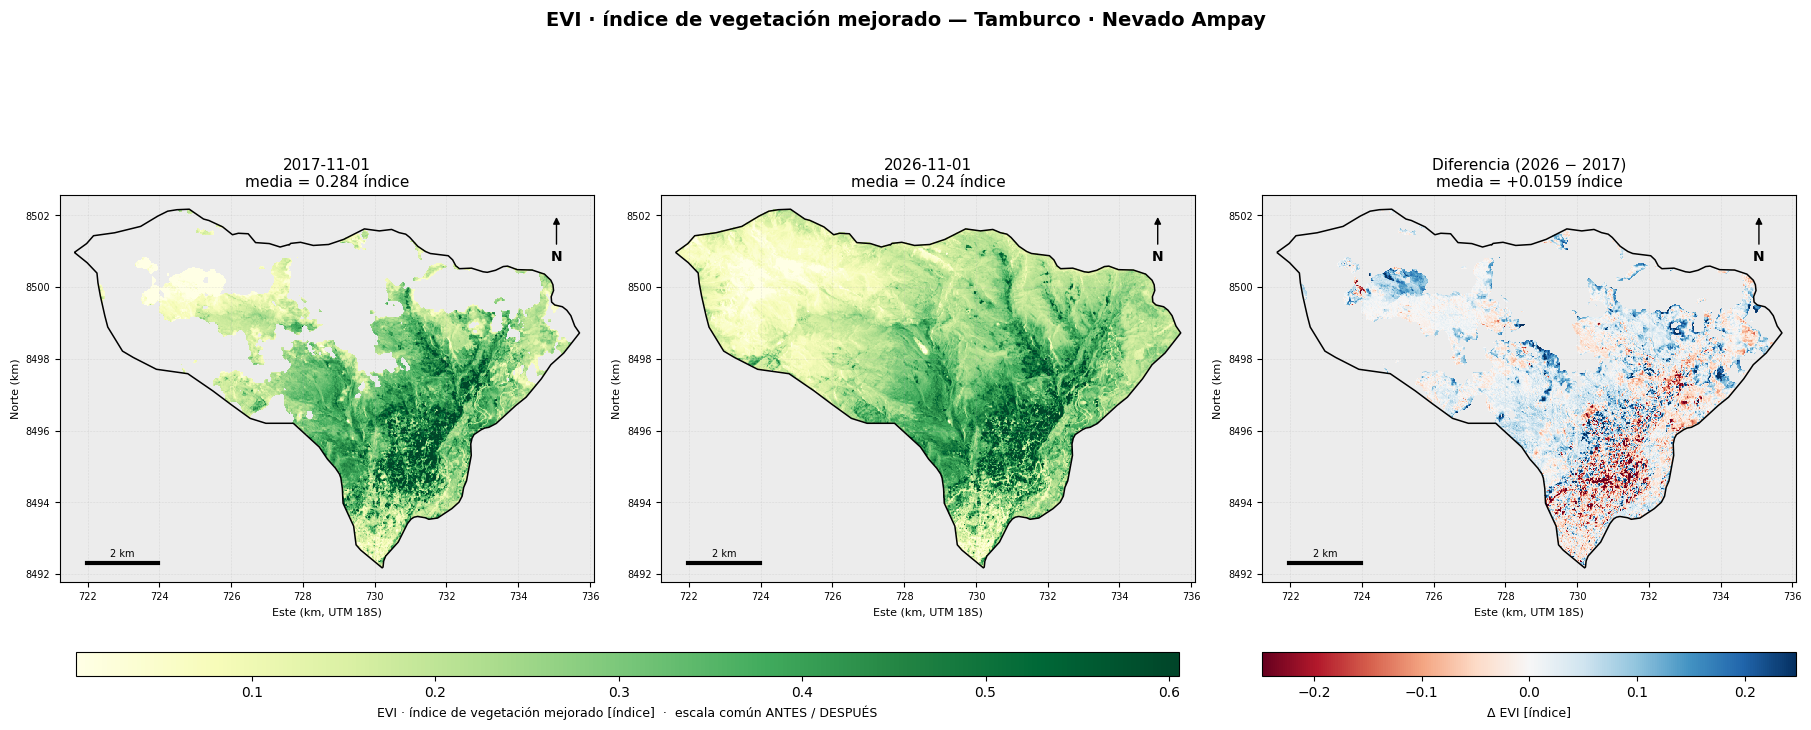

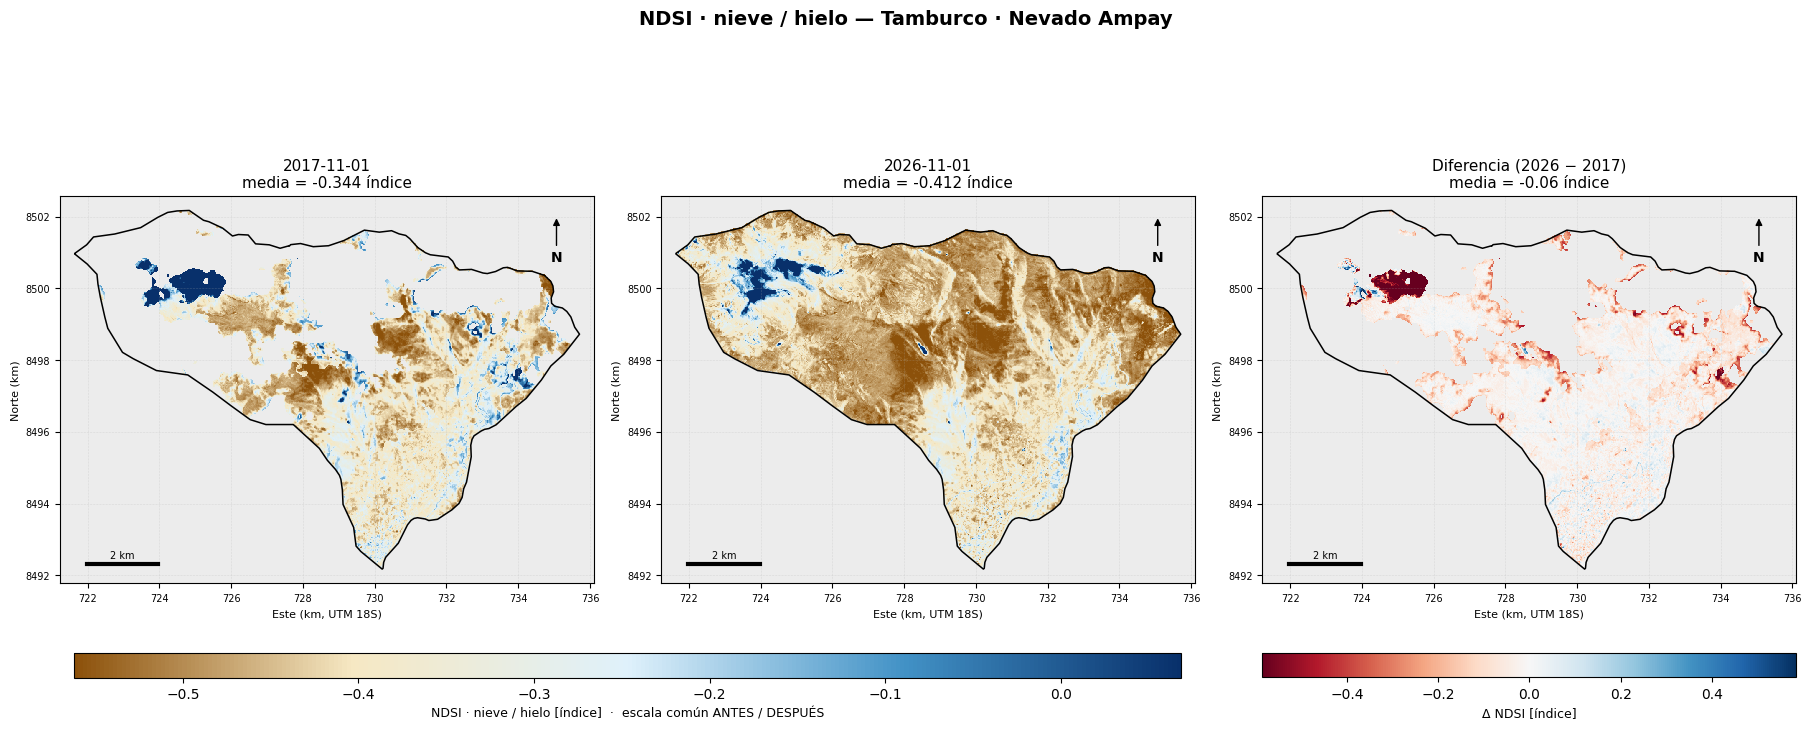

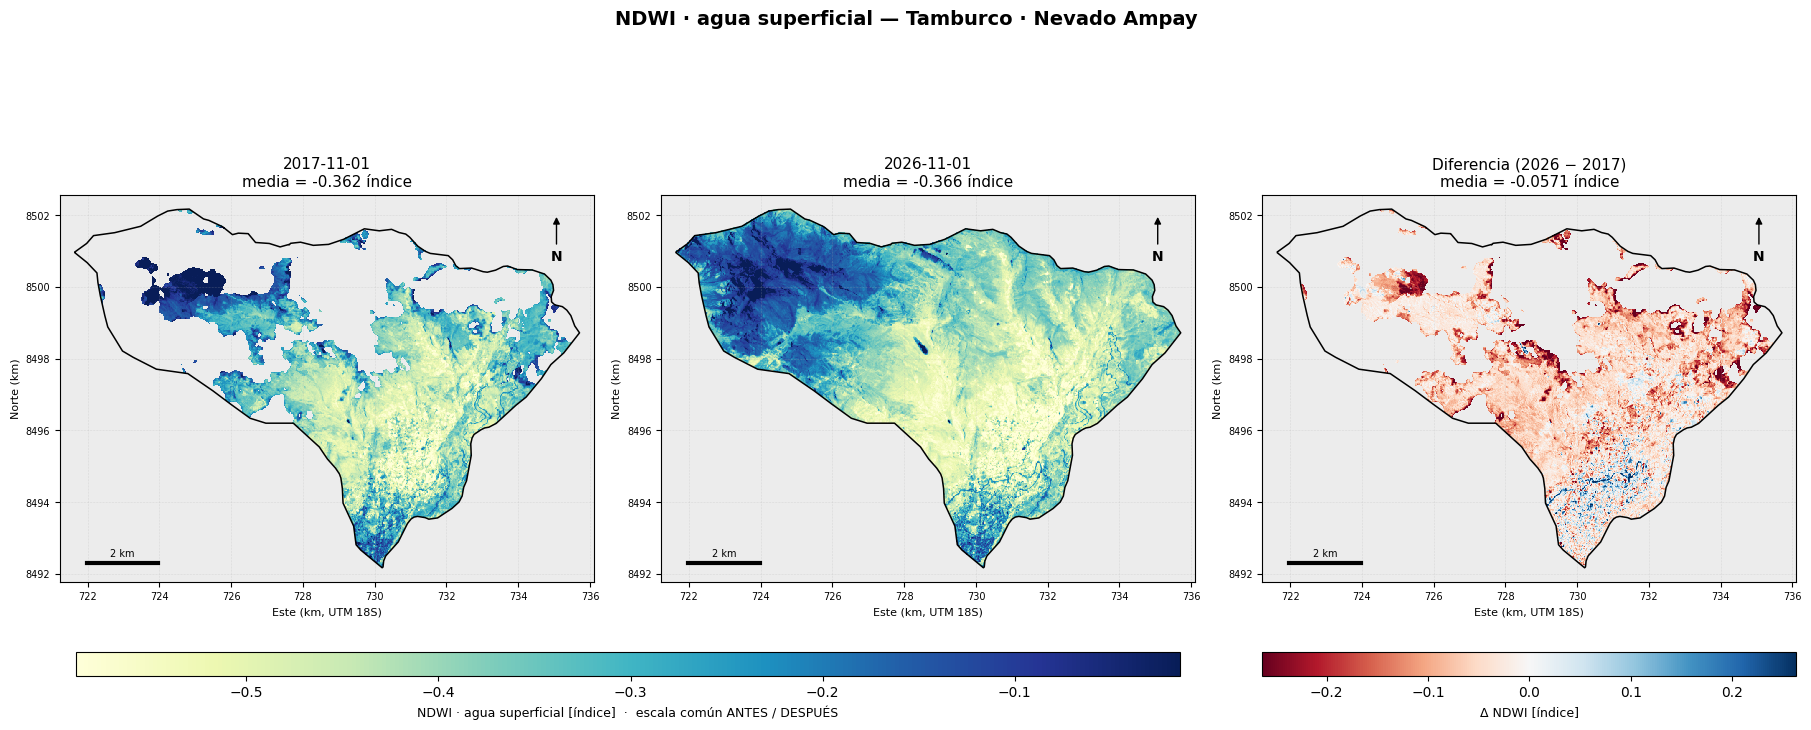

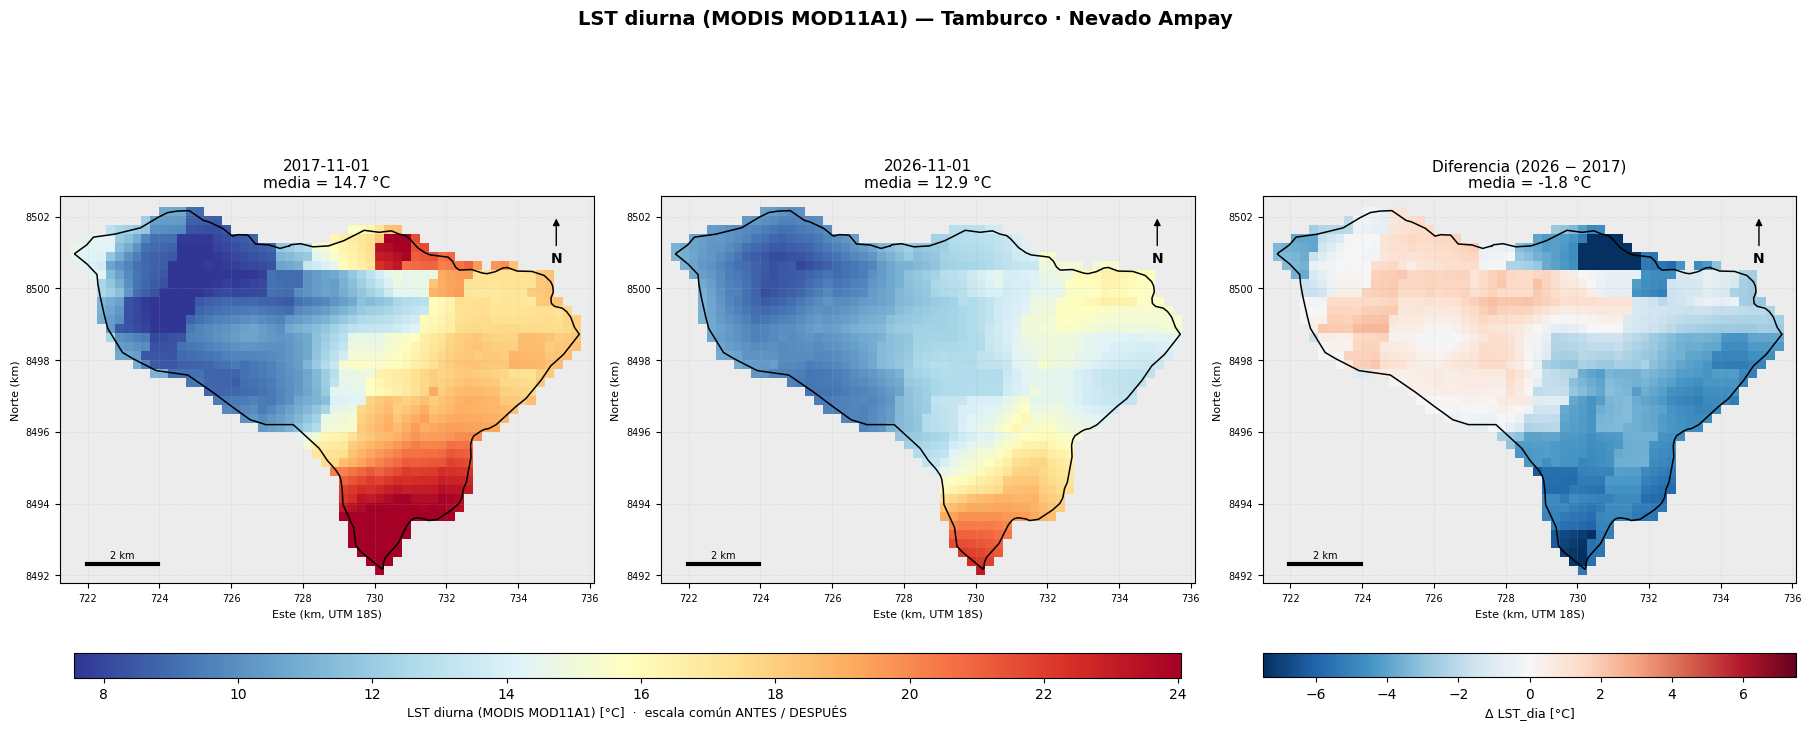

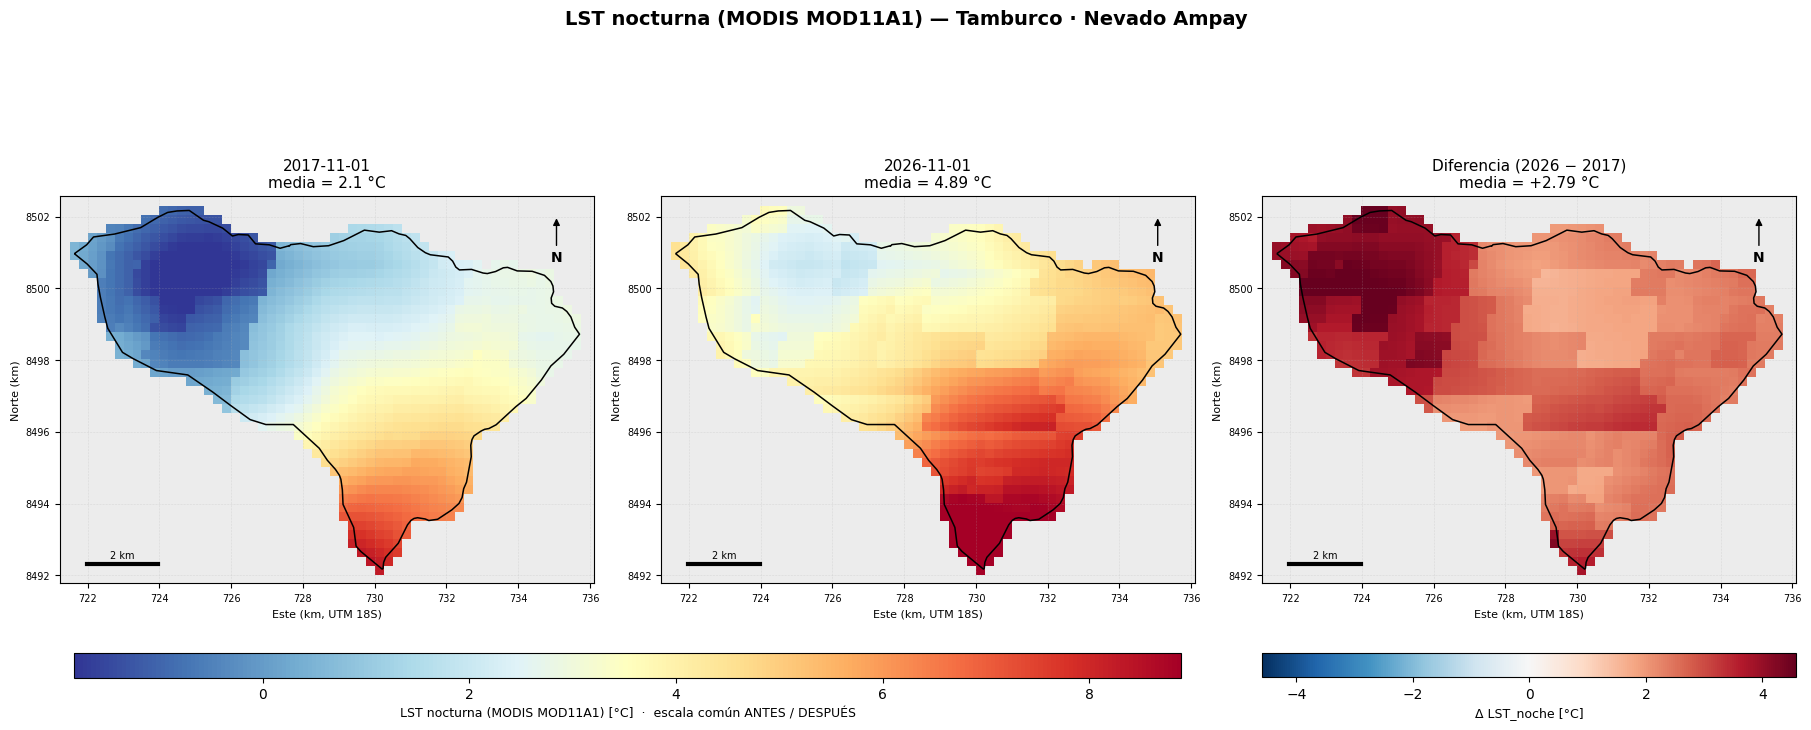

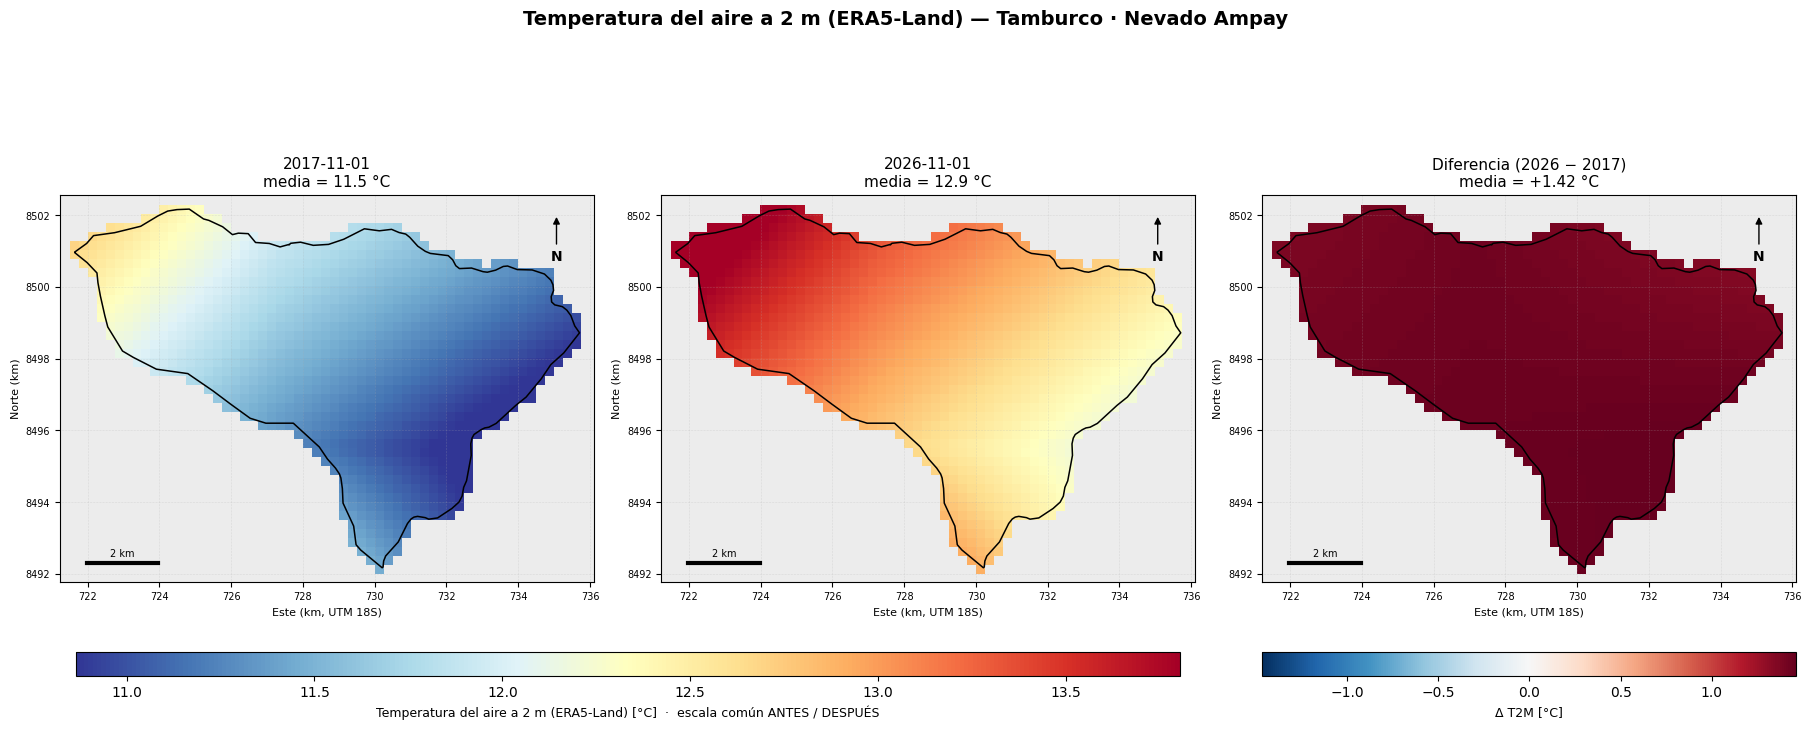

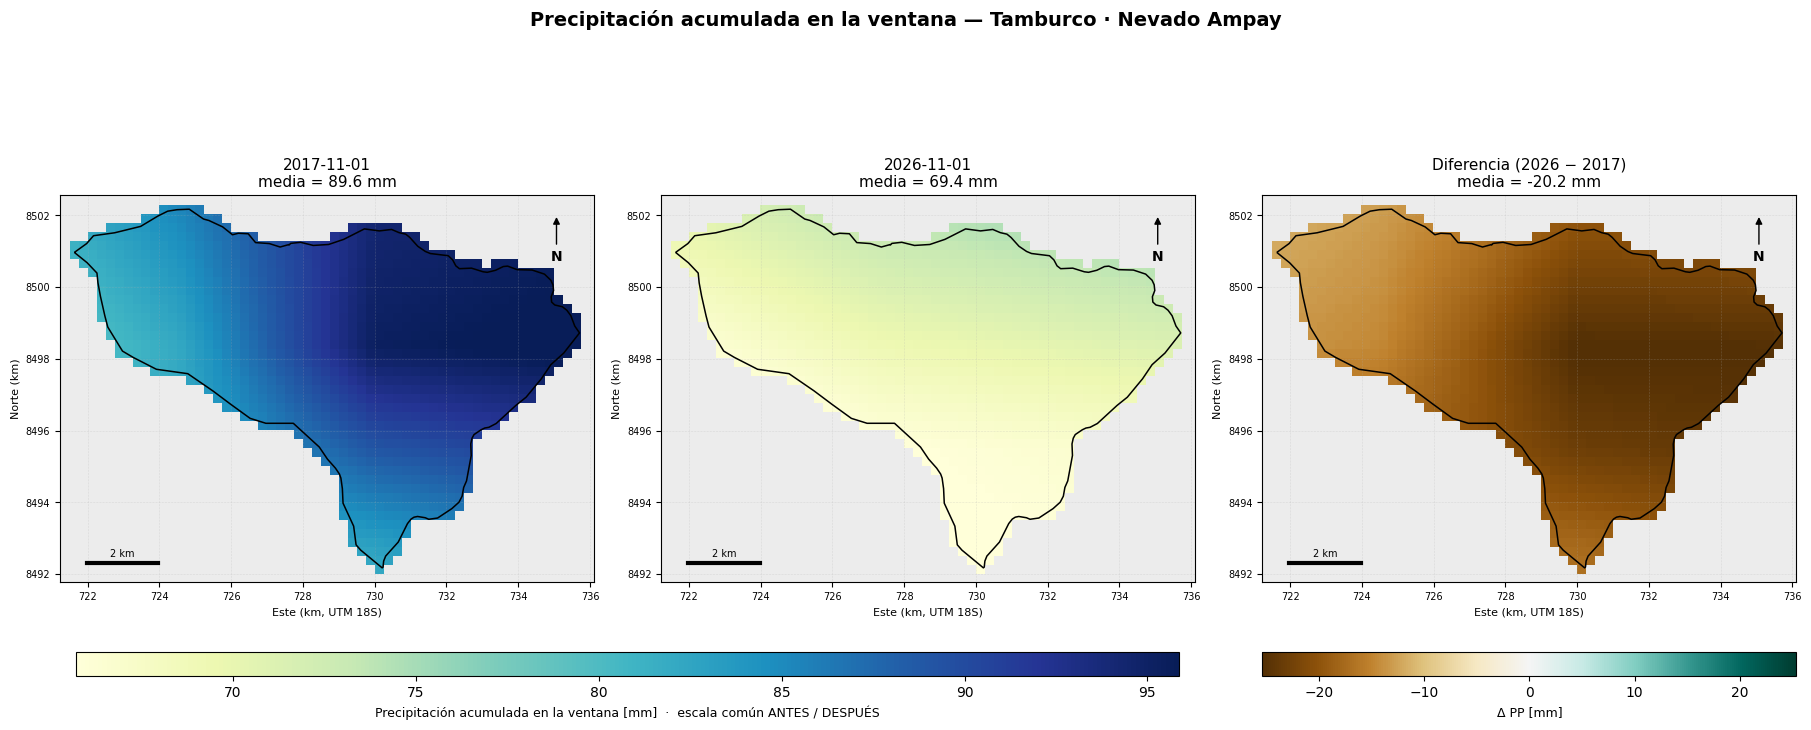

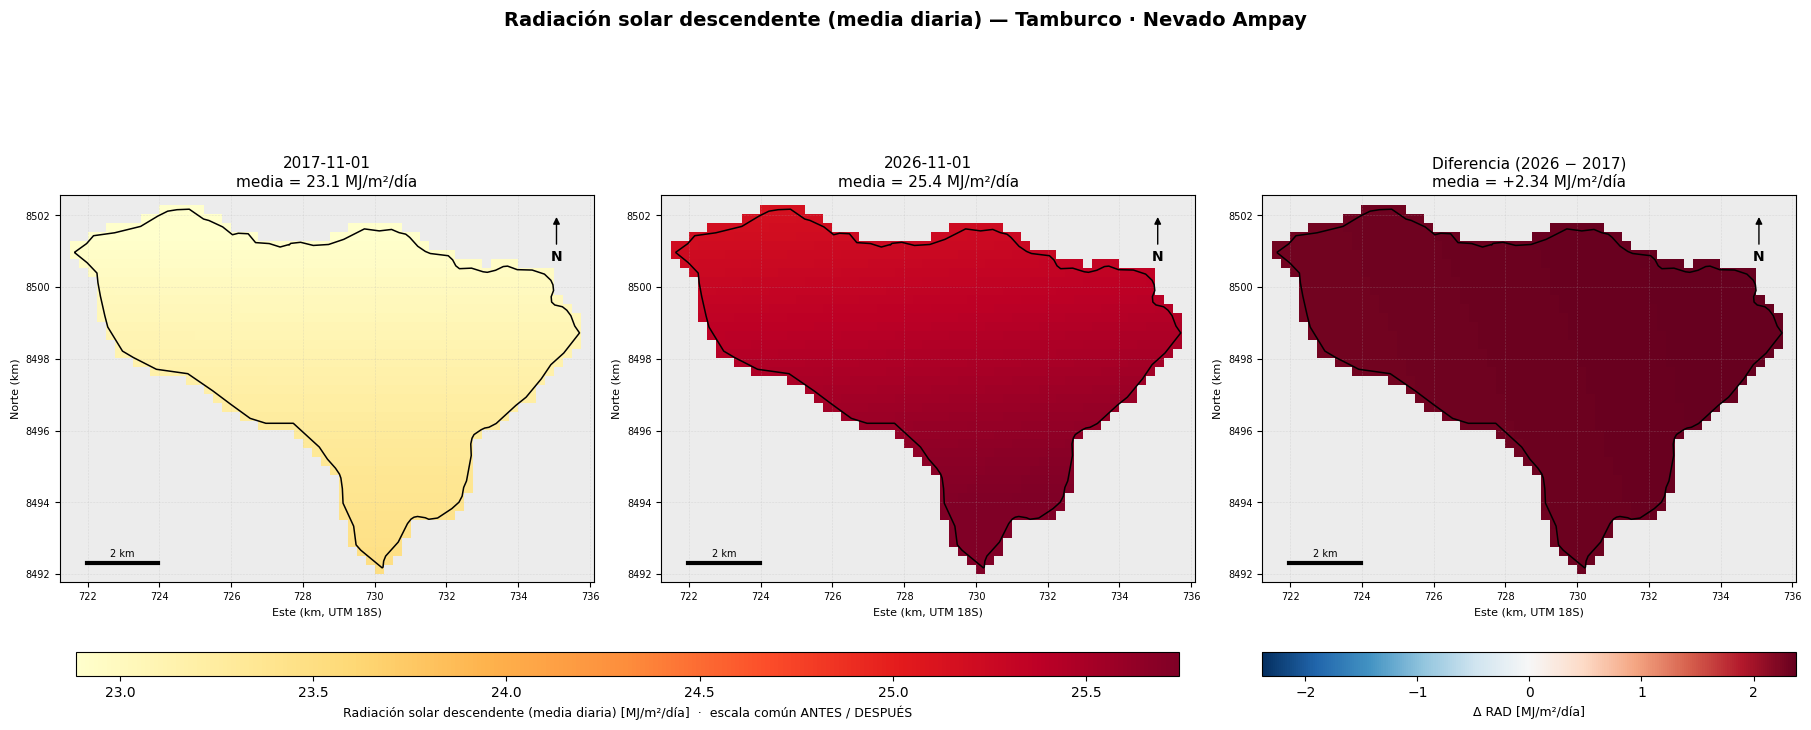

In [10]:
# ── 8. Mapas comparativos de 3 paneles (ANTES · DESPUÉS · DIFERENCIA) ───────
def extent_de(tr, shape):
    l, t = tr.c, tr.f
    return (l, l + tr.a*shape[1], t + tr.e*shape[0], t)

def decorar(ax, lim):
    ax.set_xlim(lim[0], lim[1]); ax.set_ylim(lim[2], lim[3]); ax.set_facecolor('#ececec')
    aoi.boundary.plot(ax=ax, color='black', linewidth=1.1)
    ax.set_xlim(lim[0], lim[1]); ax.set_ylim(lim[2], lim[3])
    fmt = FuncFormatter(lambda x, _: f'{x/1000:.0f}')
    ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
    ax.set_xlabel('Este (km, UTM 18S)', fontsize=8); ax.set_ylabel('Norte (km)', fontsize=8)
    ax.tick_params(labelsize=7); ax.grid(ls=':', lw=.4, alpha=.6)
    ax.annotate('N', xy=(.93, .95), xytext=(.93, .83), xycoords='axes fraction', ha='center', fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', color='k'))
    bx, by = lim[0] + (lim[1]-lim[0])*.05, lim[2] + (lim[3]-lim[2])*.05
    ax.plot([bx, bx+2000], [by, by], 'k-', lw=3); ax.text(bx+1000, by + (lim[3]-lim[2])*.015, '2 km', ha='center', fontsize=7)

mx = 400
LIM = (aoi.total_bounds[0]-mx, aoi.total_bounds[2]+mx, aoi.total_bounds[1]-mx, aoi.total_bounds[3]+mx)
PNG = {}
for v, r in R.items():
    cfg = VARIABLES[v]; ext = extent_de(r['transform'], r['antes'].shape)
    conj = np.concatenate([r['antes'][np.isfinite(r['antes'])], r['despues'][np.isfinite(r['despues'])]])
    vmin, vmax = np.percentile(conj, [2, 98]) if conj.size else (0, 1)
    if vmin == vmax: vmax = vmin + 1e-6
    dl = np.nanpercentile(np.abs(r['dif']), 98) if np.isfinite(r['dif']).any() else 1
    dl = max(dl, 1e-6)
    fig, axs = plt.subplots(1, 3, figsize=(18, 7.2), constrained_layout=True)
    for ax, tipo, f in [(axs[0], 'antes', FECHA_ANTES), (axs[1], 'despues', FECHA_DESPUES)]:
        im = ax.imshow(r[tipo], extent=ext, cmap=cfg['cmap'], vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(f"{f}\nmedia = {np.nanmean(r[tipo]):.3g} {cfg['unidad']}", fontsize=11); decorar(ax, LIM)
    cb = fig.colorbar(im, ax=axs[:2], orientation='horizontal', fraction=.045, pad=.06, aspect=45)
    cb.set_label(f"{cfg['nombre']} [{cfg['unidad']}]  ·  escala común ANTES / DESPUÉS", fontsize=9)
    imd = axs[2].imshow(r['dif'], extent=ext, cmap=cfg['dif'], vmin=-dl, vmax=dl, interpolation='nearest')
    axs[2].set_title(f"Diferencia ({FECHA_DESPUES[:4]} − {FECHA_ANTES[:4]})\nmedia = {np.nanmean(r['dif']):+.3g} {cfg['unidad']}", fontsize=11); decorar(axs[2], LIM)
    cb2 = fig.colorbar(imd, ax=axs[2], orientation='horizontal', fraction=.045, pad=.06, aspect=22)
    cb2.set_label(f"Δ {v} [{cfg['unidad']}]", fontsize=9)
    fig.suptitle(f"{cfg['nombre']} — Tamburco · Nevado Ampay", fontsize=14, fontweight='bold')
    nombre_png = f'{v}_{FECHA_ANTES}_vs_{FECHA_DESPUES}.png'
    fig.savefig(D['png']/nombre_png, dpi=200, facecolor='white'); PNG[v] = nombre_png
    plt.show(); plt.close(fig)

In [11]:
# ── 9. Exportación: CSV, JSON, GeoJSON y SQL (Supabase / geoportal AMPAY VIVO)
ST.to_csv(D['csv']/'estadisticas_zonales.csv', index=False, encoding='utf-8-sig')

prod = []
for v, r in R.items():
    cfg = VARIABLES[v]; fuente = {'opt':'Sentinel-2 HARMONIZED (mediana, Cloud Score+)'}.get(cfg['grupo'], None)
    if cfg['grupo'] == 'clim':
        fuente = {'LST_dia':'MODIS MOD11A1 v061','LST_noche':'MODIS MOD11A1 v061','T2M':'ERA5-Land DAILY_AGGR',
                  'RAD':'ERA5-Land DAILY_AGGR','PP': INFO['despues'].get('fuente_pp','CHIRPS Daily')}[v]
    for tipo, f in [('antes', FECHA_ANTES), ('despues', FECHA_DESPUES), ('diferencia', None)]:
        s = ST[(ST.variable == v) & (ST.tipo == tipo)].iloc[0]
        prod.append(dict(id=f'{v}_{tipo}', variable=v, nombre=cfg['nombre'], tipo=tipo, fecha=f,
            fecha_antes=FECHA_ANTES, fecha_despues=FECHA_DESPUES, unidad=cfg['unidad'],
            resolucion_m=r['esc'], resolucion_nativa_m=cfg['res_nat'], fuente=fuente, crs=CRS,
            geotiff=f"geotiff/{RUTAS[(v, tipo)]}", png=f"png/{PNG[v]}",
            bbox_oeste=BBOX_WGS84[0], bbox_sur=BBOX_WGS84[1], bbox_este=BBOX_WGS84[2], bbox_norte=BBOX_WGS84[3],
            media=s.media, minimo=s.minimo, maximo=s.maximo, p5=s.p5, p95=s.p95, desv=s.desv))
PR = pd.DataFrame(prod)
PR.to_csv(D['csv']/'supabase_productos.csv', index=False, encoding='utf-8-sig')

aoi.to_crs(4326)[['geometry']].assign(nombre='Tamburco - Nevado Ampay', area_km2=round(AREA_KM2, 3)) \
   .to_file(D['datos']/'area_estudio_wgs84.geojson', driver='GeoJSON')

nieve = ST[(ST.variable == 'NDSI') & ST.area_nieve_km2.notna()].set_index('tipo').area_nieve_km2
manifest = dict(
    proyecto='AMPAY VIVO', area='Tamburco - Nevado Ampay (Abancay, Apurímac)', area_km2=round(AREA_KM2, 3),
    crs=CRS, bbox_wgs84=BBOX_WGS84, fechas=dict(antes=FECHA_ANTES, despues=FECHA_DESPUES),
    ventana_dias=dict(atras=VENT_ATRAS, adelante=VENT_ADELANTE), umbral_nieve_ndsi=UMBRAL_NIEVE,
    area_nieve_km2=dict(antes=round(float(nieve['antes']), 3), despues=round(float(nieve['despues']), 3),
                        cambio=round(float(nieve['despues'] - nieve['antes']), 3)),
    metadatos_gee=INFO, generado=dt.datetime.now().isoformat(timespec='seconds'),
    nota='Clima (LST, T2M, PP, RAD) exportado a 250 m con remuestreo bilineal; la resolución nativa es mayor (ver resolucion_nativa_m).',
    productos=json.loads(PR.to_json(orient='records', force_ascii=False)))
(D['json']/'manifest_geoportal.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

SQL = """-- Supabase (PostGIS) · AMPAY VIVO
create extension if not exists postgis;
create table if not exists public.ampay_productos_raster (
  id text primary key, variable text not null, nombre text,
  tipo text check (tipo in ('antes','despues','diferencia')),
  fecha date, fecha_antes date, fecha_despues date, unidad text,
  resolucion_m numeric, resolucion_nativa_m numeric, fuente text, crs text,
  geotiff text, png text,
  bbox_oeste double precision, bbox_sur double precision, bbox_este double precision, bbox_norte double precision,
  media double precision, minimo double precision, maximo double precision,
  p5 double precision, p95 double precision, desv double precision,
  creado_en timestamptz default now());
create table if not exists public.ampay_area_estudio (
  id serial primary key, nombre text, area_km2 numeric, geom geometry(Geometry, 4326));
-- 1) Sube geotiff/ y png/ a un bucket de Storage; 2) importa csv/supabase_productos.csv;
-- 3) carga datos/area_estudio_wgs84.geojson en ampay_area_estudio (ogr2ogr o QGIS).
"""
(D['json']/'supabase_schema.sql').write_text(SQL, encoding='utf-8')

print('✔ Todo guardado en:', CARPETA)
for p in sorted(CARPETA.rglob('*')):
    if p.is_file(): print(f'  {str(p.relative_to(CARPETA)):62s} {p.stat().st_size/1024:9.1f} KB')

✔ Todo guardado en: /content/drive/MyDrive/AMPAY_VIVO_Comparacion_2017_2026
  csv/estadisticas_zonales.csv                                         5.3 KB
  csv/supabase_productos.csv                                          13.6 KB
  datos/area_estudio_wgs84.geojson                                     5.5 KB
  datos/tamburco_glaciar/tamburco_glaciar.cpg                          0.0 KB
  datos/tamburco_glaciar/tamburco_glaciar.dbf                          0.7 KB
  datos/tamburco_glaciar/tamburco_glaciar.prj                          0.4 KB
  datos/tamburco_glaciar/tamburco_glaciar.shp                          2.0 KB
  datos/tamburco_glaciar/tamburco_glaciar.shx                          0.1 KB
  datos/tamburco_glaciar.zip                                           3.3 KB
  geotiff/EVI_2017-11-01.tif                                         486.4 KB
  geotiff/EVI_2026-11-01.tif                                         818.3 KB
  geotiff/EVI_dif_2017-11-01_2026-11-01.tif                       